# nanoGPT — Member 2 (32 experiments)

**Assignment:** `block_size=64`, **`n_layer=6`**. Vary `n_head` (4, 8), `n_embd` (128, 256), `batch_size` (8, 16), `max_iters` (1000, 2000), `dropout` (0.1, 0.2).

**Run in order:** (1) setup → (2) settings → (3) helpers → (4) preflight → (5) pipeline → (6) one complete pilot → (7) remaining 31 experiments → (8–10) results and export. **Do not click Run all until the pilot is validated.**

Matches Tharun's Member 1 data, nanoGPT commit, seed and training/evaluation commands; saves Member 2 outputs in **your own Google Drive folder**. All experiments train from scratch. The pilot is real Run 01 and will be skipped automatically when running the full grid.


In [1]:
# (KEEP) 1 — Verify GPU; install dependency, pin nanoGPT commit, prepare identical dataset.
from pathlib import Path
import os, sys, subprocess, hashlib, json, time, re, itertools, threading, csv, shutil, traceback
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

SOURCE_COMMIT = '3adf61e154c3fe3fca428ad6bc3818b27a3b8291'
SOURCE_DATA_SHA = '86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed'
repo = Path('/content/nanoGPT')
if not torch.cuda.is_available():
    raise RuntimeError('Select Runtime > Change runtime type > T4 GPU, then rerun.')

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'tiktoken'], check=True)
if not (repo / '.git').is_dir():
    subprocess.run(['git', 'clone', '-q', 'https://github.com/karpathy/nanoGPT.git', str(repo)], check=True)
if subprocess.run(['git', '-C', str(repo), 'cat-file', '-e', SOURCE_COMMIT+'^{commit}'],
                  check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL).returncode:
    subprocess.run(['git', '-C', str(repo), 'fetch', '-q', 'origin', SOURCE_COMMIT], check=True)
subprocess.run(['git', '-C', str(repo), 'checkout', '-q', '-f', SOURCE_COMMIT], check=True)
commit_id = subprocess.check_output(['git', '-C', str(repo), 'rev-parse', 'HEAD'], text=True).strip()
assert commit_id == SOURCE_COMMIT
os.chdir(repo)
subprocess.run([sys.executable, 'data/shakespeare_char/prepare.py'], check=True)
dataset_path = repo / 'data/shakespeare_char/input.txt'
dataset_sha256 = hashlib.sha256(dataset_path.read_bytes()).hexdigest()
assert dataset_sha256 == SOURCE_DATA_SHA, ('Dataset differs from Member 1; do not proceed', dataset_sha256)

# Compatibility with PyTorch >=2.6: loading *self-generated* checkpoints in sample.py.
sample_py = repo / 'sample.py'
sample_src = sample_py.read_text(encoding='utf-8')
old_load = 'torch.load(ckpt_path, map_location=device)'
new_load = 'torch.load(ckpt_path, map_location=device, weights_only=False)'
if old_load in sample_src:
    sample_py.write_text(sample_src.replace(old_load, new_load, 1), encoding='utf-8')
elif new_load not in sample_src:
    raise RuntimeError('Unexpected sample.py checkpoint-loading code; stop and inspect.')

print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)
print('Commit match:', commit_id == SOURCE_COMMIT, commit_id)
print('Dataset match:', dataset_sha256 == SOURCE_DATA_SHA)
print('Setup PASSED — identical source revision and dataset.')

GPU: Tesla T4
PyTorch: 2.14.1+cu130
Commit match: True 3adf61e154c3fe3fca428ad6bc3818b27a3b8291
Dataset match: True
Setup PASSED — identical source revision and dataset.


In [2]:
# (KEEP) 2 — Member 2 settings, unique experiment grid, persistent output directory.
USE_DRIVE = True  # Keeps results across Colab runtime disconnects.
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS = Path('/content/drive/MyDrive/nanoGPT_Member2_Results')
else:
    RESULTS = repo / 'nanoGPT_Member2_Results'  # NOT persistent after runtime reset!
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 1337  # train.py internally sets torch.manual_seed(1337) on one GPU.
FIXED = {'block_size': 64, 'n_layer': 6}
N_HEADS = (4, 8)
N_EMBDS = (128, 256)
BATCH_SIZES = (8, 16)
MAX_ITERS = (1000, 2000)
DROPOUTS = (0.1, 0.2)

configs=[]
for run_id, (heads, embd, batch, steps, drop) in enumerate(
    itertools.product(N_HEADS, N_EMBDS, BATCH_SIZES, MAX_ITERS, DROPOUTS), 1
):
    assert embd % heads == 0
    configs.append({
        'run_id':run_id, 'block_size':64, 'n_layer':6,
        'n_head':heads, 'n_embd':embd, 'batch_size':batch,
        'max_iters':steps, 'dropout':drop,
    })
assert len(configs)==32 and len({(c['n_head'],c['n_embd'],c['batch_size'],c['max_iters'],c['dropout']) for c in configs})==32
assert all(c['block_size']==64 and c['n_layer']==6 for c in configs)
pd.DataFrame(configs).to_csv(RESULTS/'member2_experiment_grid.csv', index=False)
(RESULTS/'provenance.json').write_text(json.dumps({
    'nanoGPT_commit':commit_id, 'dataset_sha256':dataset_sha256,
    'member':2, 'fixed_parameters':FIXED,
    'seed_in_train_py':1337, 'torch_version':torch.__version__,
    'assumptions':'single CUDA GPU; trained from scratch; no --seed config override',
}, indent=2, default=str), encoding='utf-8')
print('Member 2: 32 unique configurations.')
print('Result folder:',RESULTS)
display(pd.DataFrame(configs).head(8))
# Train locally for comparable wall-clock times; copy each completed run to Drive.
LOCAL_RUNS = repo/'nanoGPT_Member2_Working'
LOCAL_RUNS.mkdir(exist_ok=True)


Mounted at /content/drive
Member 2: 32 unique configurations.
Result folder: /content/drive/MyDrive/nanoGPT_Member2_Results


,run_id,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout
0,1,64,6,4,128,8,1000,0.1
1,2,64,6,4,128,8,1000,0.2
2,3,64,6,4,128,8,2000,0.1
3,4,64,6,4,128,8,2000,0.2
4,5,64,6,4,128,16,1000,0.1
5,6,64,6,4,128,16,1000,0.2
6,7,64,6,4,128,16,2000,0.1
7,8,64,6,4,128,16,2000,0.2


In [3]:
# (KEEP) 3 — Training and sampling helpers. Same commands as Member 1.
EVAL_PATTERN = re.compile(r'step\s+(\d+):\s+train loss\s+([\d.]+),\s+val loss\s+([\d.]+)')


def gpu_total_used_mib():
    """GPU-wide memory used, sampled at intervals, not precise per-model peak."""
    try:
        p = subprocess.run(['nvidia-smi','--query-gpu=memory.used',
                            '--format=csv,noheader,nounits'], text=True,
                           capture_output=True, timeout=5, check=False)
        lines = [line.strip().split()[0] for line in p.stdout.splitlines() if line.strip()]
        return max(float(x) for x in lines) if lines else float('nan')
    except Exception:
        return float('nan')


def run_logged(command, log_path, monitor_gpu=False):
    """Stream important output to Colab while writing every output line to disk."""
    log_path=Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    finished=threading.Event()
    observed=[]
    def monitor():
        while not finished.is_set():
            v = gpu_total_used_mib()
            if np.isfinite(v): observed.append(v)
            finished.wait(1.0)
    t = threading.Thread(target=monitor, daemon=True) if monitor_gpu else None
    if t: t.start()
    env=os.environ.copy()
    env['PYTHONUNBUFFERED']='1'
    proc=subprocess.Popen([str(x) for x in command], cwd=repo,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, env=env)
    tail=[]
    try:
        with log_path.open('w',encoding='utf-8') as log:
            for line in proc.stdout:
                log.write(line)
                log.flush()
                tail.append(line.rstrip())
                if len(tail)>35: tail.pop(0)
                line_low=line.lower()
                if ('step ' in line_low or 'saving checkpoint' in line_low
                    or 'number of parameters' in line_low or 'error' in line_low
                    or 'traceback' in line_low or 'warning' in line_low):
                    print(line.rstrip())
        rc=proc.wait()
    finally:
        finished.set()
        if t: t.join(timeout=3)
    if rc != 0:
        raise RuntimeError('Training/sampling failed. See '+str(log_path)
                          +'\nLast lines:\n'+'\n'.join(tail[-18:]))
    return max(observed) if observed else float('nan')


def training_command(cfg, out, preflight=False):
    return [sys.executable,'train.py','config/train_shakespeare_char.py',
        '--device=cuda','--compile=False', '--init_from=scratch',
        '--gradient_accumulation_steps=1','--always_save_checkpoint=True',
        '--eval_interval='+str(1 if preflight else 200),
        '--eval_iters='+str(2 if preflight else 40),
        '--log_interval='+str(1 if preflight else 100),
        '--out_dir='+str(out),
        '--block_size='+str(cfg['block_size']),
        '--n_layer='+str(cfg['n_layer']),
        '--n_head='+str(cfg['n_head']),
        '--n_embd='+str(cfg['n_embd']),
        '--batch_size='+str(cfg['batch_size']),
        '--max_iters='+str(2 if preflight else cfg['max_iters']),
        '--lr_decay_iters='+str(2 if preflight else cfg['max_iters']),
        '--dropout='+str(cfg['dropout'])]


def sample_command(out):
    return [sys.executable,'sample.py','--out_dir='+str(out),
        '--device=cuda','--compile=False','--seed='+str(SEED),
        '--num_samples=1','--max_new_tokens=300',
        '--temperature=0.8','--top_k=20']


def eval_history(log_path):
    text=Path(log_path).read_text(encoding='utf-8')
    rows=[(int(it),float(train),float(val)) for it,train,val in EVAL_PATTERN.findall(text)]
    return pd.DataFrame(rows,columns=['iteration','train_loss','val_loss'])


def count_unique_parameters(ckpt_path):
    # Only open checkpoints generated by this notebook. Never unpickle unknown files.
    from model import GPT, GPTConfig
    ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    net = GPT(GPTConfig(**ckpt['model_args']))
    result=sum(p.numel() for p in net.parameters())  # tied weights counted once
    del ckpt,net
    return int(result)


def plot_one(history, path, title):
    fig, ax=plt.subplots(figsize=(7.2,4))
    ax.plot(history.iteration,history.train_loss,marker='o',label='Training')
    ax.plot(history.iteration,history.val_loss,marker='o',label='Validation')
    ax.set(xlabel='Iteration',ylabel='Cross-entropy loss',title=title)
    ax.legend(); ax.grid(alpha=0.25)
    fig.tight_layout(); fig.savefig(path,dpi=170); plt.close(fig)

In [4]:
# (UTILITY) 4 — Two-step preflight only: tests compatibility, NOT an assignment result.
preflight_dir=RESULTS/'_preflight'
preflight_dir.mkdir(parents=True,exist_ok=True)
print('Preflight: 2 short training iterations (NOT an assignment result).')
run_logged(training_command(configs[0], preflight_dir, preflight=True),
           preflight_dir/'training.log',monitor_gpu=True)
preflight_ckpt=preflight_dir/'ckpt.pt'
if not preflight_ckpt.exists():
    raise RuntimeError('Preflight checkpoint not found; inspect _preflight/training.log.')
run_logged(sample_command(preflight_dir),preflight_dir/'sample.log')
print('PREFLIGHT PASSED: checkpoint saved and sample.py generated text.')
print('Sample preview (last 600 characters):')
print((preflight_dir/'sample.log').read_text(encoding='utf-8')[-600:])

Preflight: 2 short training iterations (NOT an assignment result).
number of parameters: 1.19M
/content/nanoGPT/train.py:196: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
step 0: train loss 4.1814, val loss 4.1779
step 1: train loss 4.1714, val loss 4.1646
saving checkpoint to /content/drive/MyDrive/nanoGPT_Member2_Results/_preflight
step 2: train loss 4.1372, val loss 4.1350
saving checkpoint to /content/drive/MyDrive/nanoGPT_Member2_Results/_preflight
number of parameters: 1.19M
PREFLIGHT PASSED: checkpoint saved and sample.py generated text.
Sample preview (last 600 characters):
preflight
Overriding: device = cuda
Overriding: compile = False
Overriding: seed = 1337
Overriding: num_samples = 1
Overriding: max_new_tokens = 300
Overriding: temperature = 0.8
Overriding: top_k = 20
number of parameters: 1.19M
Loading meta from data/shakespeare_char/meta.pkl...


ql;xxMRRZ:Ndco?j,SO  LFT,eb$G';aAGeoouBFSSOG:

In [5]:
# (KEEP) 5 — Resumable pipeline. Completed runs are skipped if checkpoint remains available.
SUMMARY_FILE=RESULTS/'experiment_summary.csv'
if SUMMARY_FILE.exists():
    summary=pd.read_csv(SUMMARY_FILE)
    records={int(r['run_id']):r for r in summary.to_dict('records')}
else:
    records={}


def save_summary():
    rows=[records[k] for k in sorted(records)]
    pd.DataFrame(rows).to_csv(SUMMARY_FILE,index=False)


def run_one(cfg):
    i=cfg['run_id']
    run_dir=LOCAL_RUNS/f'run_{i:02d}'
    persist_dir=RESULTS/f'run_{i:02d}'
    ckpt_dir=run_dir/'checkpoint'
    ckpt=ckpt_dir/'ckpt.pt'
    if i in records and records[i].get('status')=='complete' and (persist_dir/'checkpoint'/'ckpt.pt').is_file():
        print(f'Run {i:02d}/32: already complete, skipping.')
        return
    run_dir.mkdir(parents=True,exist_ok=True)
    ckpt_dir.mkdir(parents=True,exist_ok=True)
    (run_dir/'config.json').write_text(json.dumps(cfg,indent=2),encoding='utf-8')
    command=training_command(cfg,ckpt_dir)
    (run_dir/'command.txt').write_text(' '.join(command),encoding='utf-8')
    print(f'\nRUN {i:02d}/32 | heads={cfg["n_head"]}, embd={cfg["n_embd"]}, '
          f'batch={cfg["batch_size"]}, iterations={cfg["max_iters"]}, dropout={cfg["dropout"]}')
    t0=time.perf_counter()
    try:
        observed_gpu_mib=run_logged(command,run_dir/'training.log',monitor_gpu=True)
        elapsed=time.perf_counter()-t0
        if not ckpt.is_file():
            raise RuntimeError(f'Run {i}: checkpoint missing. See {run_dir/"training.log"}')
        history=eval_history(run_dir/'training.log')
        if history.empty:
            raise RuntimeError(f'Run {i}: no evaluation metrics parsed.')
        history.to_csv(run_dir/'loss_history.csv',index=False)
        plot_one(history,run_dir/'loss_curve.png',f'Run {i:02d}: training versus validation')
        # Sampling failures are real failures: don't silently mark run complete.
        run_logged(sample_command(ckpt_dir),run_dir/'sample.txt',monitor_gpu=False)
        last=history.iloc[-1]
        record={**cfg, 'status':'complete',
            'final_train_loss':float(last.train_loss),
            'final_val_loss':float(last.val_loss),
            'best_val_loss':float(history.val_loss.min()),
            'loss_gap':float(last.val_loss-last.train_loss),
            'wall_seconds':round(elapsed,2),
            'parameter_count':count_unique_parameters(ckpt),
            'gpu_used_mib_sampled_peak':observed_gpu_mib,
            'training_tokens_approx':cfg['block_size']*cfg['batch_size']*(cfg['max_iters']+1),
            'run_folder':str(persist_dir),
        }
        # Persist artifacts AFTER timing training, to avoid Drive I/O skewing comparisons.
        shutil.copytree(run_dir, persist_dir, dirs_exist_ok=True)
        if not (persist_dir/'checkpoint'/'ckpt.pt').is_file():
            raise RuntimeError('Could not verify persisted checkpoint in Drive.')
        records[i]=record
        save_summary()
        print(f'Completed {i:02d}/32; val={record["final_val_loss"]:.4f}, '
              f'time={elapsed/60:.1f} min')
    except Exception as exc:
        # Preserve any partial logs to aid debugging after a disconnect.
        try: shutil.copytree(run_dir, persist_dir, dirs_exist_ok=True)
        except Exception: pass
        records[i]={**cfg,'status':'failed','error':str(exc),'run_folder':str(run_dir)}
        save_summary()
        raise RuntimeError(f'STOPPED on run {i:02d}; see {run_dir}/training.log '
                           'or sample.txt. Fix the error, then rerun this cell. '
                           'Already completed runs will be skipped.') from exc



In [6]:
# (UTILITY) 6 — Pilot: run full Experiment 01 and inspect output before running 31 more.
# This IS a required Member 2 experiment; it is recorded and will not rerun unless incomplete.
run_one(configs[0])
print('Pilot complete. Review the printed losses, checkpoint and sample before proceeding.')
print('Run 01 configuration:', configs[0])
print('Run 01 summary:', records.get(1))
print('Sample preview:')
print((RESULTS/'run_01'/'sample.txt').read_text(encoding='utf-8')[-500:])

Run 01/32: already complete, skipping.
Pilot complete. Review the printed losses, checkpoint and sample before proceeding.
Run 01 configuration: {'run_id': 1, 'block_size': 64, 'n_layer': 6, 'n_head': 4, 'n_embd': 128, 'batch_size': 8, 'max_iters': 1000, 'dropout': 0.1}
Run 01 summary: {'run_id': 1, 'block_size': 64, 'n_layer': 6, 'n_head': 4, 'n_embd': 128, 'batch_size': 8, 'max_iters': 1000, 'dropout': 0.1, 'status': 'complete', 'final_train_loss': 2.251, 'final_val_loss': 2.2553, 'best_val_loss': 2.2553, 'loss_gap': 0.0043000000000001, 'wall_seconds': 26.62, 'parameter_count': 1197824, 'gpu_used_mib_sampled_peak': 201.0, 'training_tokens_approx': 512512, 'run_folder': '/content/drive/MyDrive/nanoGPT_Member2_Results/run_01'}
Sample preview:
num_samples = 1
Overriding: max_new_tokens = 300
Overriding: temperature = 0.8
Overriding: top_k = 20
number of parameters: 1.19M
Loading meta from data/shakespeare_char/meta.pkl...

CANCIO:
Rory cowingh is sor thibe seak oue tontanth ther meagata

In [7]:
# (KEEP) 7 — Run/resume the full 32-experiment Member 2 grid.
# Only run after confirming the pilot output with your instructor/assistant.
for cfg in configs:
    run_one(cfg)
summary_check = pd.read_csv(RESULTS/'experiment_summary.csv')
completed_check = summary_check[summary_check.status == 'complete']
if len(completed_check) != 32:
    raise RuntimeError(f'Only {len(completed_check)}/32 completed: investigate before exporting.')
print('ALL 32 MEMBER 2 EXPERIMENTS COMPLETED.')

Run 01/32: already complete, skipping.
Run 02/32: already complete, skipping.
Run 03/32: already complete, skipping.
Run 04/32: already complete, skipping.
Run 05/32: already complete, skipping.
Run 06/32: already complete, skipping.
Run 07/32: already complete, skipping.
Run 08/32: already complete, skipping.
Run 09/32: already complete, skipping.
Run 10/32: already complete, skipping.
Run 11/32: already complete, skipping.
Run 12/32: already complete, skipping.
Run 13/32: already complete, skipping.
Run 14/32: already complete, skipping.
Run 15/32: already complete, skipping.
Run 16/32: already complete, skipping.
Run 17/32: already complete, skipping.
Run 18/32: already complete, skipping.
Run 19/32: already complete, skipping.
Run 20/32: already complete, skipping.
Run 21/32: already complete, skipping.
Run 22/32: already complete, skipping.
Run 23/32: already complete, skipping.
Run 24/32: already complete, skipping.
Run 25/32: already complete, skipping.
Run 26/32: already comple

Completed: 32/32. Best observed configuration:


,run_id,block_size,n_layer,n_head,n_embd,batch_size,max_iters,dropout,status,final_train_loss,final_val_loss,best_val_loss,loss_gap,wall_seconds,parameter_count,gpu_used_mib_sampled_peak,training_tokens_approx,run_folder
0,31,64,6,8,256,16,2000,0.1,complete,1.5695,1.7471,1.7471,0.1776,50.34,4754944,335.0,2049024,/content/drive/MyDrive/nanoGPT_Member2_Results...
1,15,64,6,4,256,16,2000,0.1,complete,1.5752,1.7522,1.7522,0.1770,49.29,4754944,325.0,2049024,/content/drive/MyDrive/nanoGPT_Member2_Results...
2,32,64,6,8,256,16,2000,0.2,complete,1.6401,1.8053,1.8053,0.1652,49.08,4754944,335.0,2049024,/content/drive/MyDrive/nanoGPT_Member2_Results...
3,16,64,6,4,256,16,2000,0.2,complete,1.6583,1.8270,1.8270,0.1687,50.78,4754944,325.0,2049024,/content/drive/MyDrive/nanoGPT_Member2_Results...
4,27,64,6,8,256,8,2000,0.1,complete,1.7546,1.8767,1.8767,0.1221,49.24,4754944,273.0,1024512,/content/drive/MyDrive/nanoGPT_Member2_Results...
5,11,64,6,4,256,8,2000,0.1,complete,1.7606,1.8847,1.8847,0.1241,48.58,4754944,267.0,1024512,/content/drive/MyDrive/nanoGPT_Member2_Results...
6,29,64,6,8,256,16,1000,0.1,complete,1.8064,1.9032,1.9032,0.0968,27.63,4754944,335.0,1025024,/content/drive/MyDrive/nanoGPT_Member2_Results...
7,13,64,6,4,256,16,1000,0.1,complete,1.8043,1.9048,1.9048,0.1005,27.19,4754944,325.0,1025024,/content/drive/MyDrive/nanoGPT_Member2_Results...
8,23,64,6,8,128,16,2000,0.1,complete,1.8323,1.9434,1.9392,0.1111,48.31,1197824,255.0,2049024,/content/drive/MyDrive/nanoGPT_Member2_Results...
9,7,64,6,4,128,16,2000,0.1,complete,1.8449,1.9494,1.9420,0.1045,49.45,1197824,227.0,2049024,/content/drive/MyDrive/nanoGPT_Member2_Results...


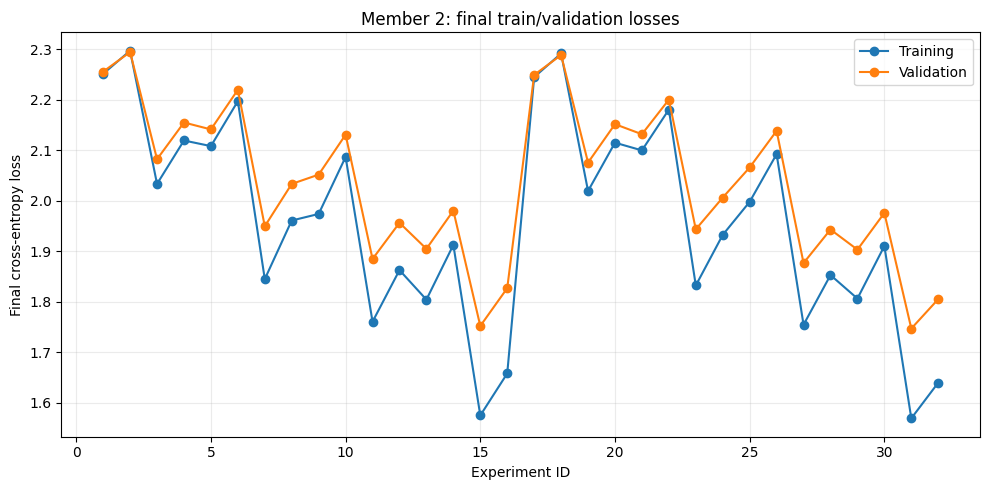

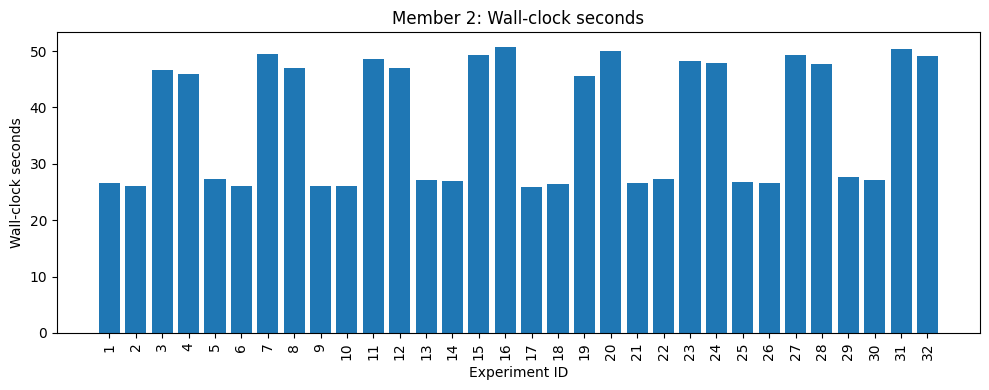

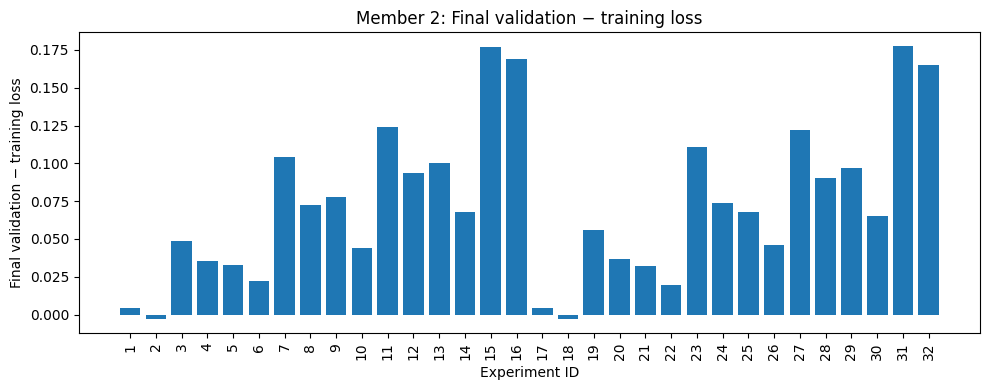

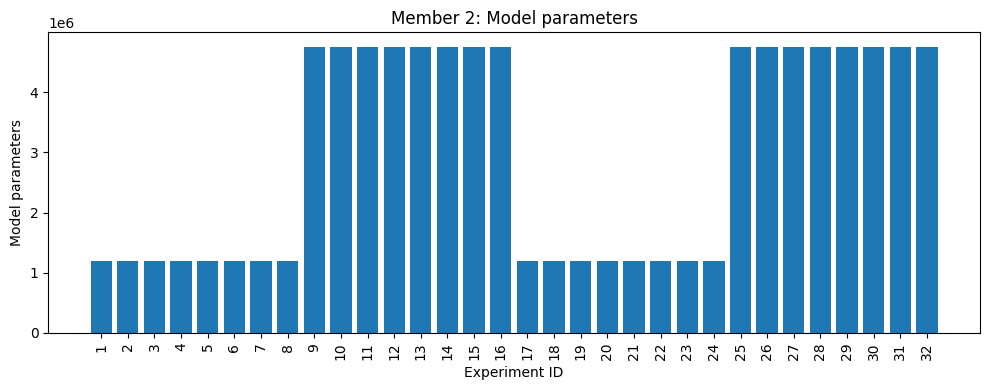

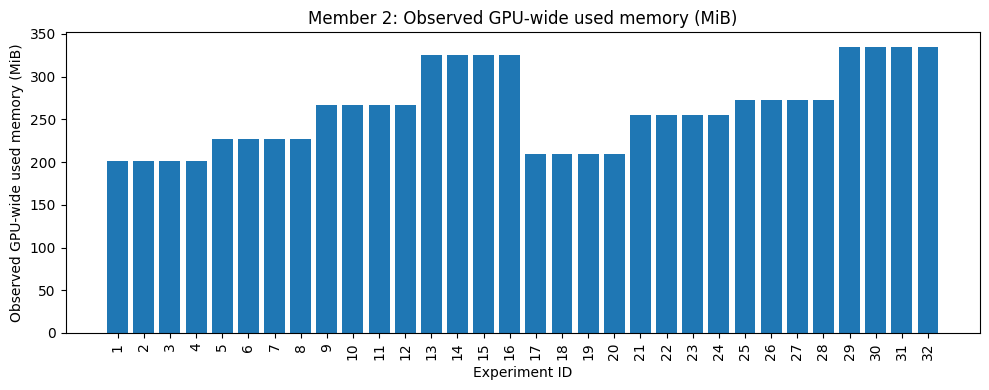

In [8]:
# (RESULT) 8 — Ranking and results visualizations (partial or complete).
summary=pd.read_csv(RESULTS/'experiment_summary.csv')
completed=summary.loc[summary.status=='complete'].copy()
if completed.empty:
    raise RuntimeError('No completed experiments yet. Run the preflight and experiments first.')
ranked=completed.sort_values(['best_val_loss','wall_seconds']).reset_index(drop=True)
ranked.to_csv(RESULTS/'ranked_experiments.csv',index=False)
print(f'Completed: {len(completed)}/32. Best observed configuration:')
display(ranked.head(10))

fig,ax=plt.subplots(figsize=(10,5))
x=completed.sort_values('run_id')
ax.plot(x.run_id,x.final_train_loss,marker='o',label='Training')
ax.plot(x.run_id,x.final_val_loss,marker='o',label='Validation')
ax.set(xlabel='Experiment ID',ylabel='Final cross-entropy loss',
       title='Member 2: final train/validation losses')
ax.legend();ax.grid(alpha=0.25);fig.tight_layout()
fig.savefig(RESULTS/'comparison_final_losses.png',dpi=180);plt.show()

for column, ylabel, filename in [
    ('wall_seconds','Wall-clock seconds','comparison_training_time.png'),
    ('loss_gap','Final validation − training loss','comparison_loss_gap.png'),
    ('parameter_count','Model parameters','comparison_parameter_count.png'),
    ('gpu_used_mib_sampled_peak','Observed GPU-wide used memory (MiB)','comparison_gpu_memory.png'),
]:
    fig,ax=plt.subplots(figsize=(10,4))
    ax.bar(x.run_id.astype(str),x[column])
    ax.set(xlabel='Experiment ID',ylabel=ylabel,title='Member 2: '+ylabel)
    ax.tick_params(axis='x',labelrotation=90)
    fig.tight_layout();fig.savefig(RESULTS/filename,dpi=180);plt.show()

In [9]:
# (RESULT) 9 — Factorial comparisons and generated text from the best run.
metrics=['final_train_loss','final_val_loss','best_val_loss',
         'loss_gap','wall_seconds','parameter_count']
frames=[]
for hp in ('n_head','n_embd','batch_size','max_iters','dropout'):
    effect=completed.groupby(hp,dropna=False)[metrics].mean().reset_index()
    effect.insert(0,'hyperparameter',hp)
    effect=effect.rename(columns={hp:'value'})
    frames.append(effect)
effects=pd.concat(frames,ignore_index=True)
effects.to_csv(RESULTS/'hyperparameter_effects.csv',index=False)
print('Hyperparameter averages (interpret with care if fewer than all 32 runs are complete):')
display(effects)

best_dir=Path(ranked.iloc[0].run_folder)
print('Best validation model:',best_dir)
print('Generated sample excerpt:')
print((best_dir/'sample.txt').read_text(encoding='utf-8')[-900:])

Hyperparameter averages (interpret with care if fewer than all 32 runs are complete):


,hyperparameter,value,final_train_loss,final_val_loss,best_val_loss,loss_gap,wall_seconds,parameter_count
0,n_head,4.0,1.965288,2.038544,2.037812,0.073256,37.326250,2976384.0
1,n_head,8.0,1.958625,2.031244,2.030737,0.072619,37.640625,2976384.0
2,n_embd,128.0,2.095300,2.135869,2.134631,0.040569,37.071875,1197824.0
3,n_embd,256.0,1.828612,1.933919,1.933919,0.105306,37.895000,4754944.0
4,batch_size,8.0,2.046919,2.099800,2.099800,0.052881,36.935000,2976384.0
5,batch_size,16.0,1.876994,1.969988,1.968750,0.092994,38.031875,2976384.0
6,max_iters,1000.0,2.078250,2.120531,2.120531,0.042281,26.665625,2976384.0
7,max_iters,2000.0,1.845662,1.949256,1.948019,0.103594,48.301250,2976384.0
8,dropout,0.1,1.917175,2.000819,2.000094,0.083644,37.594375,2976384.0
9,dropout,0.2,2.006737,2.068969,2.068456,0.062231,37.372500,2976384.0


Best validation model: /content/drive/MyDrive/nanoGPT_Member2_Results/run_31
Generated sample excerpt:
Overriding: out_dir = /content/nanoGPT/nanoGPT_Member2_Working/run_31/checkpoint
Overriding: device = cuda
Overriding: compile = False
Overriding: seed = 1337
Overriding: num_samples = 1
Overriding: max_new_tokens = 300
Overriding: temperature = 0.8
Overriding: top_k = 20
number of parameters: 4.74M
Loading meta from data/shakespeare_char/meta.pkl...


ANGELO:
And come, which yet that set be you way.

GLOUCESTER:
Not be that foul hath you we that ane away, my facest,
And In heavent, to that I confil now
What slife, sing in the set drove to do me not.

First Come like dispard:
As my deady so speaking him you long.
I came, this dest my low, thee ag
---------------



In [10]:
# (KEEP) 10 — Export report-ready Member 2 evidence without large model checkpoints.
# Checkpoints remain in RESULTS / run_XX / checkpoint and need not be uploaded to GitHub.
import zipfile
archive=RESULTS/'Member2_report_evidence.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in RESULTS.rglob('*'):
        if not path.is_file() or path==archive:
            continue
        if path.suffix in {'.pt','.tmp'}:  # skip model checkpoints / temporary files
            continue
        if path.name=='sample.log' and '_preflight' in path.parts: continue
        z.write(path,path.relative_to(RESULTS))
print('Created:',archive)
print('Files for report: experiment_summary.csv, ranked_experiments.csv, '
      'hyperparameter_effects.csv, comparison charts, individual loss plots, '
      'samples, commands and logs.')

Created: /content/drive/MyDrive/nanoGPT_Member2_Results/Member2_report_evidence.zip
Files for report: experiment_summary.csv, ranked_experiments.csv, hyperparameter_effects.csv, comparison charts, individual loss plots, samples, commands and logs.


In [11]:
# (UTILITY) 11 — Download evidence ZIP to your computer for report/team handoff.
from google.colab import files
files.download(str(archive))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

from pathlib import Path
import pandas as pd
import json
import re

base = Path("/content/drive/MyDrive/nanoGPT_Member2_Results")
summary = pd.read_csv(base / "experiment_summary.csv")

checks = []

for _, run in summary.sort_values("run_id").iterrows():
    i = int(run["run_id"])
    folder = base / f"run_{i:02d}"

    files = {
        "config": folder / "config.json",
        "log": folder / "training.log",
        "history": folder / "loss_history.csv",
        "sample": folder / "sample.txt",
        "plot": folder / "loss_curve.png",
        "checkpoint": folder / "checkpoint" / "ckpt.pt",
    }

    present = {k: p.is_file() for k, p in files.items()}

    config_match = False
    if present["config"]:
        config = json.loads(files["config"].read_text())
        config_match = all(
            config.get(k) == int(run[k])
            for k in ["run_id", "block_size", "n_layer",
                      "n_head", "n_embd", "batch_size",
                      "max_iters"]
        ) and abs(float(config["dropout"]) -
                  float(run["dropout"])) < 1e-9

    last_step = None
    if present["log"]:
        log = files["log"].read_text()
        matches = re.findall(
            r"step\s+(\d+):\s+train loss\s+[\d.]+,\s+val loss\s+[\d.]+",
            log
        )
        if matches:
            last_step = int(matches[-1])

    complete = (
        run["status"] == "complete"
        and all(present.values())
        and config_match
        and last_step == int(run["max_iters"])
    )

    checks.append({
        "Run": i,
        "Layers": int(run["n_layer"]),
        "Heads": int(run["n_head"]),
        "Embeddings": int(run["n_embd"]),
        "Last Eval": last_step,
        "Expected": int(run["max_iters"]),
        "Best Val Loss": round(float(run["best_val_loss"]), 4),
        "Time (s)": round(float(run["wall_seconds"]), 2),
        "Config Match": config_match,
        "Files Present": all(present.values()),
        "Check": "PASS" if complete else "REVIEW"
    })

check_df = pd.DataFrame(checks)

print("MEMBER 2 — ALL EXPERIMENT VERIFICATION")
print("-" * 60)
display(check_df)

passed = (check_df["Check"] == "PASS").sum()
print(f"\nVerification: {passed}/32 passed")

if passed == 32:
    print("All 32 saved records passed these checks.")
else:
    print("Some records need investigation.")


MEMBER 2 — ALL EXPERIMENT VERIFICATION
------------------------------------------------------------


,Run,Layers,Heads,Embeddings,Last Eval,Expected,Best Val Loss,Time (s),Config Match,Files Present,Check
0,1,6,4,128,1000,1000,2.2553,26.62,True,True,PASS
1,2,6,4,128,1000,1000,2.2940,26.11,True,True,PASS
2,3,6,4,128,2000,2000,2.0821,46.71,True,True,PASS
3,4,6,4,128,2000,2000,2.1547,45.90,True,True,PASS
4,5,6,4,128,1000,1000,2.1410,27.39,True,True,PASS
5,6,6,4,128,1000,1000,2.2194,26.07,True,True,PASS
6,7,6,4,128,2000,2000,1.9420,49.45,True,True,PASS
7,8,6,4,128,2000,2000,2.0289,47.02,True,True,PASS
8,9,6,4,256,1000,1000,2.0516,26.03,True,True,PASS
9,10,6,4,256,1000,1000,2.1306,26.10,True,True,PASS



Verification: 32/32 passed
All 32 saved records passed these checks.


In [13]:

from pathlib import Path
import re

base = Path("/content/drive/MyDrive/nanoGPT_Member2_Results")

# Change to a specific number, e.g. [1, 15, 31]
# to display only selected experiments.
RUNS_TO_SHOW = list(range(1, 33))

for run_id in RUNS_TO_SHOW:
    log_file = base / f"run_{run_id:02d}" / "training.log"

    print(f"\n{'=' * 65}")
    print(f"EXPERIMENT {run_id:02d} — SAVED TRAINING OUTPUT")
    print(f"{'=' * 65}")

    if not log_file.exists():
        print("Training log missing!")
        continue

    lines = log_file.read_text(encoding="utf-8").splitlines()

    for line in lines:
        if re.search(
            r"step\s+\d+:|number of parameters|saving checkpoint",
            line,
            re.IGNORECASE
        ):
            print(line)



EXPERIMENT 01 — SAVED TRAINING OUTPUT
number of parameters: 1.19M
step 0: train loss 4.1897, val loss 4.1839
step 200: train loss 2.5450, val loss 2.5314
saving checkpoint to /content/nanoGPT/nanoGPT_Member2_Working/run_01/checkpoint
step 400: train loss 2.4386, val loss 2.4526
saving checkpoint to /content/nanoGPT/nanoGPT_Member2_Working/run_01/checkpoint
step 600: train loss 2.3335, val loss 2.3398
saving checkpoint to /content/nanoGPT/nanoGPT_Member2_Working/run_01/checkpoint
step 800: train loss 2.2651, val loss 2.2728
saving checkpoint to /content/nanoGPT/nanoGPT_Member2_Working/run_01/checkpoint
step 1000: train loss 2.2510, val loss 2.2553
saving checkpoint to /content/nanoGPT/nanoGPT_Member2_Working/run_01/checkpoint

EXPERIMENT 02 — SAVED TRAINING OUTPUT
number of parameters: 1.19M
step 0: train loss 4.1897, val loss 4.1839
step 200: train loss 2.5484, val loss 2.5316
saving checkpoint to /content/nanoGPT/nanoGPT_Member2_Working/run_02/checkpoint
step 400: train loss 2.4509, 